In [1]:
!pip install networkx[default]

In [2]:
!pip install geopandas shapely matplotlib

In [3]:
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import random
import numpy as np
import datetime
import time
from tqdm import tqdm
import math
import numpy as np
import heapq
import copy
import json
import pickle
from collections import defaultdict

In [4]:
def haversine_distances(G, u, v):
    lat1 = math.radians(G.nodes[u]['y'])
    lon1 = math.radians(G.nodes[u]['x'])
    lat2 = math.radians(G.nodes[v]['y'])
    lon2 = math.radians(G.nodes[v]['x'])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = math.sin(dlat / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2) ** 2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    return 6371000 * c

In [ ]:
import pandas as pd
import geopandas as gpd
def expand_edges_by_oneway(edges: pd.DataFrame) -> pd.DataFrame:
    new_edges = []

    for idx, row in edges.iterrows():
        u, v = row['u'], row['v']
        length = row.get('length')
        if length == None or u == v:
            continue
        oneway = str(row.get('oneway')).lower()
        row_data = row.to_dict()

        if oneway == 'yes':
            new_edges.append({**row_data, 'u': u, 'v': v})
        elif oneway == '-1':
            new_edges.append({**row_data, 'u': v, 'v': u})
        elif oneway in ['no', 'none', 'nan']:
            new_edges.append({**row_data, 'u': u, 'v': v})
            new_edges.append({**row_data, 'u': v, 'v': u})
        else:
            new_edges.append({**row_data, 'u': u, 'v': v})
            new_edges.append({**row_data, 'u': v, 'v': u})
    new_edges = pd.DataFrame(new_edges)
    edges_clean = gpd.GeoDataFrame(new_edges, geometry=new_edges['geometry'], crs=edges.crs)
    
    return edges_clean

def preprocess_graph(G):
    id_map = {nid: i for i, nid in enumerate(G.nodes)}
    G = nx.relabel_nodes(G, id_map, copy=True)
    
    edges_to_remove = []

    for u, v, k, data in G.edges(keys=True, data=True):
        if data.get('length') is None:
            edges_to_remove.append((u, v, k))

    G.remove_edges_from(edges_to_remove)

    edges_to_add = []
    edges_to_remove = []

    for u, v, k, data in G.edges(keys=True, data=True):
        oneway = str(data.get('oneway')).lower()
        if u == v:
            edges_to_remove.append((u, v, k))
            continue
        
        if oneway == 'yes':
            continue
        elif oneway == '-1':
            edges_to_add.append((v, u, data.copy()))
            edges_to_remove.append((u, v, k))
        elif oneway in ['no', 'none', 'nan']:
            edges_to_add.append((v, u, data.copy()))
        else:
            edges_to_add.append((v, u, data.copy()))

    for u, v, k in edges_to_remove:
        G.remove_edge(u, v, key=k)
    
    for u, v, data in edges_to_add:
        G.add_edge(u, v, **data)

    return G

In [6]:
graph = None
with open("/kaggle/input/graph-networkx/graph-hochiminhcity.pkl", "rb") as f:
    graph = pickle.load(f)

In [7]:
print(type(graph))

<class 'networkx.classes.multidigraph.MultiDiGraph'>


In [ ]:
bidirectional_edges = set()
unidirectional_edges = set()

for u, v, k in graph.edges(keys=True):
    if graph.has_edge(v, u):
        bidirectional_edges.add(tuple(sorted((u, v))))
    else:
        unidirectional_edges.add((u, v))

# unidirectional_edges = {e for e in unidirectional_edges if tuple(sorted(e)) not in bidirectional_edges}

print("Cạnh hai chiều:", len(bidirectional_edges))
print("Cạnh một chiều:", len(unidirectional_edges))

Cạnh hai chiều: 599049
Cạnh một chiều: 0


In [9]:
print(len(graph.nodes))
print(len(graph.edges))

550935
1198098


In [10]:
nodes = list(graph.nodes)
N = int(len(nodes) / 10)
sample_nodes = random.sample(nodes, N)

In [11]:
lons = [graph.nodes[n]["x"] for n in sample_nodes]
lats = [graph.nodes[n]["y"] for n in sample_nodes]

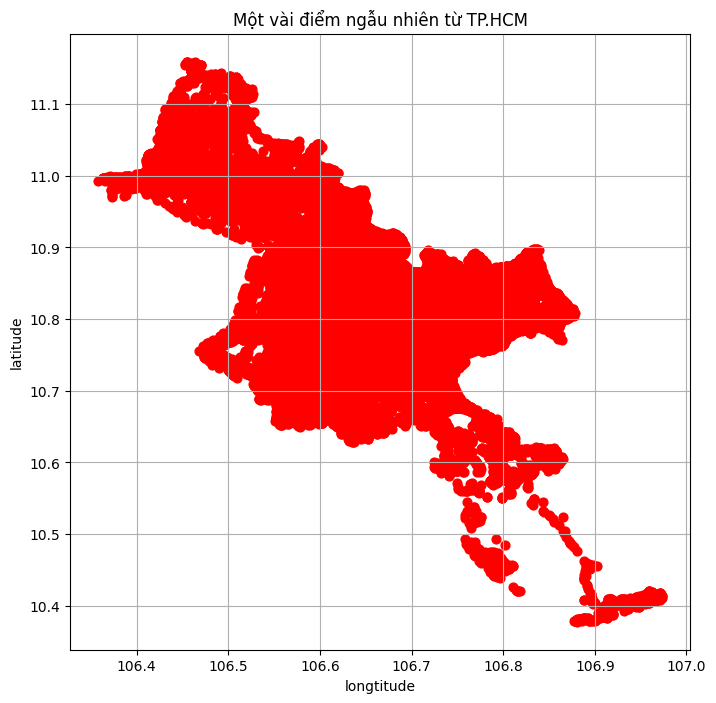

In [12]:
plt.figure(figsize=(8, 8))
plt.scatter(lons, lats, c="red", s=40)

plt.title("Một vài điểm ngẫu nhiên từ TP.HCM")
plt.xlabel("longtitude")
plt.ylabel("latitude")
plt.grid(True)
plt.show()

In [13]:
print(len(graph.edges))

1198098


In [14]:

class ContractionHierarchies:
    def __init__(self, graph):
        self.new_edges = []
        self.sto_shortcut = []
        self.G = copy.deepcopy(graph)
        self.n = self.G.number_of_nodes()
        self.nodes_order = [None] * self.n
        self.order_nodes = [None] * self.n
        self.need_recompute = [None] * self.n
        self.shortcut = {}
        self.weight_backward = {}
        self.weight = self._init_weight()
        

    def _init_weight(self):
        weight = {}
        for node in self.G.nodes:
            if node not in weight:
                weight[node] = {}
            for _, v, w1 in list(self.G.out_edges(node, data='length')):
                if v not in weight[node] or w1 < weight[node][v]:
                    weight[node][v] = w1
                
            for u, _, w2 in list(self.G.in_edges(node, data='length')):
                if u not in weight:
                    weight[u] = {}
                if node not in weight[u] or w2 < weight[u][node]:
                    weight[u][node] = w2
            
        self.new_edges = []
        for u in weight.keys():
            if u not in self.shortcut:
                self.shortcut[u] = {}
            for v, w in weight[u].items():
                self.new_edges.append((u, v, w, -1))
                self.shortcut[u][v] = -1
        return weight
        
    def dijkstra_path_local_seach(self, source, target=None, avoid_node=None, threshold=None, hop = -1, theta=50):
        pq = [(0, source, 0)]
        dis = {source: 0}
                    
        visited = set()
        
        while len(pq) > 0 and len(visited) <= theta:
            cur_dis, u, cnt_edge = heapq.heappop(pq)

            if u == target:
                break
            if u == avoid_node or u in visited:
                continue
            if hop != -1 and cnt_edge >= hop:
                continue
            if threshold is not None and cur_dis > threshold:
                continue
            visited.add(u)
            
            for v in list(self.G.successors(u)):
                if v == avoid_node:
                    continue
    
                dis_v = cur_dis + self.weight[u][v]
                if (v not in dis or dis_v < dis[v]):
                    if (threshold == None) or (threshold != None and dis_v <= threshold): 
                        dis[v] = dis_v
                        heapq.heappush(pq, (dis_v, v, cnt_edge + 1))
                    
        return dis
        
    def edge_difference(self, node):

        successors = list(self.G.successors(node))
        predecessors = list(self.G.predecessors(node))
        dif_edge = -len(successors) - len(predecessors)
        
        for u in predecessors:
            
            w2 = self.weight[u][node]
            cur_dis = {}
            limit_weight = -1e9
            for v in successors:
                
                w1 = self.weight[node][v]
                
                cur_dis[v] = w1 + w2
            if len(cur_dis) == 0:
                continue
                
            limit_weight = max(cur_dis.values())
            dis = self.dijkstra_path_local_seach(source=u, avoid_node=node, threshold = limit_weight, hop=5)

            for v in successors:
                
                if (v not in dis) or (dis[v] > cur_dis[v]):
                    dif_edge += 1

        return dif_edge
                    
    def get_nodes_order(self):
        priority_queue = []
        for node in self.G.nodes:
            edge_diff = self.edge_difference(node)
            self.need_recompute[node] = False
            heapq.heappush(priority_queue, (edge_diff, node))
        return priority_queue

    def build_contraction_hierarchy(self):
        priority_queue = self.get_nodes_order()
        cnt = 0
        total_nodes = len(priority_queue)
        while priority_queue:
            score, node = heapq.heappop(priority_queue)
            
            if self.need_recompute[node] == True:
                current_score = self.edge_difference(node)
                self.need_recompute[node] = False
                if priority_queue and current_score > priority_queue[0][0]:
                    heapq.heappush(priority_queue, (current_score, node))
                    continue
                
            
            self.nodes_order[node] = cnt 
            self.order_nodes[cnt] = node
            cnt += 1
            
            successors = list(self.G.successors(node))
            predecessors = list(self.G.predecessors(node))

            for u in predecessors:
                
                w2 = self.weight[u][node]
                cur_dis = {}
                limit_weight = -1e9
                for v in successors:
                    
                    w1 = self.weight[node][v]
                    
                    cur_dis[v] = w1 + w2
                if len(cur_dis) == 0:
                    continue

                limit_weight = max(cur_dis.values())
                dis = self.dijkstra_path_local_seach(source=u, avoid_node=node, threshold = limit_weight, hop=5)
            
                for v in successors:
                    
                    if (v not in dis) or (dis[v] > cur_dis[v]):

                        check_edge = self.G.has_edge(u, v)
                        if not check_edge:
                            self.G.add_edge(u, v)
                        self.weight[u][v] = cur_dis[v]
                        self.shortcut[u][v] = node
                            
            for u in predecessors:
                self.need_recompute[u] = True
                self.new_edges.append((u, node, self.weight[u][node], self.shortcut[u][node]))
                del self.weight[u][node], self.shortcut[u][node]
                
            for v in successors:
                self.need_recompute[v] = True
                self.new_edges.append((node, v, self.weight[node][v], self.shortcut[node][v]))
                del self.weight[node][v], self.shortcut[node][v]
                
            self.G.remove_node(node)
        self._build_new_graph()
        
    def _build_new_graph(self):
        self.weight.clear()
        self.shortcut.clear()
        self.weight = {i: {} for i in range(self.n)}
        self.shortcut = {i: {} for i in range(self.n)}
        
        for u, v, w, shortc in self.new_edges:
            if v not in self.weight[u] or w < self.weight[u][v]:
                self.weight[u][v] = w
                self.shortcut[u][v] = shortc
                if v not in self.weight_backward:
                    self.weight_backward[v] = {}
                self.weight_backward[v][u] = w

    
    def get_shortcut(self, source, target):
        shortcut_node = self.shortcut[source][target]
        if shortcut_node != -1:
            return self.get_shortcut(source, shortcut_node) + [shortcut_node] + self.get_shortcut(shortcut_node, target)
        else:
            return []
            
    def get_path(self, parent, target, forward=True):
        node = target
        path = []
        while (node != -1):
            path.append(node)
            if parent[node] != -1:
                parent_node = parent[node]
                temp_path = self.get_shortcut(parent_node, node) if forward else self.get_shortcut(node, parent_node)
                if forward:
                    temp_path.reverse()
                path += temp_path
                node = parent_node
            else:
                break
        return path

    def dijkstra_search(self, source, weight):
        pq = [(0, source)]
        dis = {source: 0}
        parent = {source: -1}
        visited = set()
        cnt_shortest_path = {source: 1}
        sto_processnode = []
        predes = {}
        
        cnt_sp = None
        
        while pq:
            cur_dis, u = heapq.heappop(pq)
            if u in visited:
                continue
            visited.add(u)

            cnt_sp = cnt_shortest_path[u]
            sto_processnode.append(u)
            
            for v in weight[u].keys():
                if self.nodes_order[u] < self.nodes_order[v]:
                    dis_v = cur_dis + weight[u][v]
                    
                    if v in dis and dis_v == dis[v]:
                        cnt_shortest_path[v] += cnt_sp
                        predes[v].append(u)
                        
                    if v not in dis or dis_v < dis[v]:
                        dis[v] = dis_v
                        parent[v] = u
                        heapq.heappush(pq, (dis_v, v))
                        
                        cnt_shortest_path[v] = cnt_sp
                        predes[v] = [u]
        return {
            'source': source,
            'dis': dis,
            'parent': parent,
            'cnt_shortest_path': cnt_shortest_path,
            'sto_processnode': sto_processnode,
            'predes': predes
        }
        
    def bidirectional_dijkstra(self, source, target=None):
        
        start = time.time()
        dijkstra_source = self.dijkstra_search(source=source, weight=self.weight)
        dis_s = dijkstra_source['dis']
        
        if target != None:
            dijkstra_target = self.dijkstra_search(source=target, weight=self.weight_backward)
            dis_t = dijkstra_target['dis']
            
            shortest_length = math.inf
            tmp = None
            path = []
            for node in dis_s:
                if node in dis_t and shortest_length > dis_s[node] + dis_t[node]:
                    tmp = node
                    shortest_length = dis_s[node] + dis_t[node]
                
        process_time = time.time() - start

        parent_s = dijkstra_source['parent']
        if target != None:
            parent_t = dijkstra_target['parent']
            
            if tmp != None:
                path_s_tmp, path_t_tmp = [], []
                if tmp != source:
                    path_s_tmp = self.get_path(parent_s, tmp)
                    path_s_tmp.reverse()
                if tmp != target:
                    path_t_tmp = self.get_path(parent_t, tmp, forward=False)
                path = path_s_tmp[:-1] + path_t_tmp
        ans = {
            'source': source,
            'latency_s': process_time,
            'cnt_shortest_path_source': dijkstra_source['cnt_shortest_path'],
            'sto_processnode_source': dijkstra_source['sto_processnode'],
            'predes_source': dijkstra_source['predes'],
        }
        if target != None:
            ans.update({
                'target': target,
                'path_length': shortest_length,
                'path_nodes': path,
                'cnt_shortest_path_target': dijkstra_target['cnt_shortest_path'],
                'sto_processnode_target': dijkstra_target['sto_processnode'],
                'predes_target': dijkstra_target['predes']
            })
        return ans

In [15]:
def shortest_path_alogrithm(G, source, target, algo='dijkstra', heuristic='haversine'):
    t0, t1 = None, None
    if algo == 'dijkstra':
        t0 = time.time()
        path = nx.dijkstra_path(G, source, target, weight='length')
        t1 = time.time()
    elif algo == 'astar':
        if heuristic == 'haversine':
            heuristic = haversine_distances
        t0 = time.time()
        path = nx.astar_path(G, source, target, heuristic=lambda u, v: heuristic(G, u, v), weight='length')
        t1 = time.time()
    else:
        raise Exception("No algo in database")
    
    return {
        "algorithm": algo,
        "source": source,
        "target": target,
        "latency_s": round((t1 - t0), 4),
        "path_length": nx.path_weight(G, path, weight='length'),
        "path_nodes": path
    }

In [16]:
def stratified_random_queries(G, k=1000, target_gen=True, seed=42, bootstrapping=True):
    random.seed(seed)
    np.random.seed(seed)

    degree_dict = dict(G.degree())
    nodes = list(G.nodes())
    
    low_deg = [n for n in nodes if degree_dict[n] <= 4]
    med_deg = [n for n in nodes if 5 <= degree_dict[n] <= 9]
    high_deg = [n for n in nodes if degree_dict[n] >= 10]

    queries = []
    k_per_group = k // 3

    def sample_group(group, num_samples, used_set=None):
        samples = []
        group = list(set(group))  # remove duplicates
        if not target_gen and not bootstrapping:
            # Loại bỏ các đỉnh đã dùng
            group = list(set(group) - used_set)
            random.shuffle(group)
            for i in range(min(num_samples, len(group))):
                u = group[i]
                samples.append(u)
                used_set.add(u)
        else:
            for _ in range(num_samples):
                if len(group) < 1 + int(target_gen):
                    break
                if target_gen:
                    u, v = random.sample(group, 2)
                    samples.append((u, v))
                else:
                    u = random.choice(group)
                    samples.append(u)
                    if not bootstrapping:
                        used_set.add(u)
                        group.remove(u)
        return samples

    used = set()
    queries.extend(sample_group(low_deg, k_per_group, used))
    queries.extend(sample_group(med_deg, k_per_group, used))
    queries.extend(sample_group(high_deg, k - len(queries), used))

    if len(queries) < k:
        remaining = k - len(queries)
        flat_pool = low_deg + med_deg + high_deg
        flat_pool = list(set(flat_pool))
        for _ in range(remaining):
            if target_gen:
                u, v = random.sample(flat_pool, 2)
                queries.append((u, v))
            else:
                u = random.choice(flat_pool)
                queries.append(u)

    return queries


In [17]:
def run_shortest_path_benchmark(G, benchmark, algo='dijkstra', heuristic='haversine'):
    log = []
    for u, v in tqdm(benchmark):
        log.append(shortest_path_alogrithm(G, u, v, algo, heuristic))
    
    now = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")  
    output_file = algo + "_" + now + ".json"
    with open(output_file, 'w') as f:
        json.dump(log, f, indent=4)

In [18]:
"sto = shortest_path_alogrithm(graph, 467588, 111568)"

'sto = shortest_path_alogrithm(graph, 467588, 111568)'

In [ ]:
queries = stratified_random_queries(graph, target_gen=True)
print(len(queries))
print(queries[:5])

'queries = stratified_random_queries(graph, target_gen=True)\nprint(len(queries))\nprint(queries[:5])'

In [ ]:
run_shortest_path_benchmark(graph, queries, algo='astar')

"run_shortest_path_benchmark(graph, queries, algo='astar')"

In [21]:
def check_valid_path(ori_graph, path):
    check_path = True
    for i in range(len(path) - 1):
        if graph.has_edge(path[i], path[i + 1]) == False:
            print(path[i], path[i + 1])
            check_path = False
    return check_path
    
def evaluate_contraction_hierachies(benchmark, ori_graph, ch):
    log = []
    for u, v in tqdm(benchmark):
        res = ch.bidirectional_dijkstra(u, v)
        filtered_res = {
            'source': res['source'],
            'target': res['target'],
            'latency_s': res['latency_s'],
            'path_length': res['path_length'],
            'path_nodes': res['path_nodes']
        }
        log.append(filtered_res)
        check_valid = check_valid_path(ori_graph, filtered_res["path_nodes"])
        if check_valid == False:
            break
    
    now = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")  
    output_file = "CH_" + now + ".json"
    with open(output_file, 'w') as f:
        json.dump(log, f, indent=4)

In [ ]:
path_astar = "/kaggle/input/benchmark-result/astar_20250615_113030.json"
path_dijkstra = "/kaggle/input/benchmark-result/dijkstra_20250611_130052.json"
path_ch = "/kaggle/working/CH_20250616_141709.json

'path_astar = "/kaggle/input/benchmark-result/astar_20250615_113030.json"\npath_dijkstra = "/kaggle/input/benchmark-result/dijkstra_20250611_130052.json"\npath_ch = "/kaggle/working/CH_20250616_141709.json'

In [ ]:
contractH = ContractionHierarchies(graph)

'contractH = ContractionHierarchies(graph)'

In [ ]:
contractH.build_contraction_hierarchy()

'contractH.build_contraction_hierarchy()'

In [ ]:
sto_contract = contractH.bidirectional_dijkstra(467588, 111568)

'sto_contract = contractH.bidirectional_dijkstra(467588, 111568)'

In [ ]:
check_valid = check_valid_path(graph, sto_contract['path_nodes']) "

"check_valid = check_valid_path(graph, sto_contract['path_nodes']) "

In [ ]:
contractH.weight[528694].keys()

'contractH.weight[528694].keys()'

In [ ]:
contractH.weight_backward[528694].keys()

'contractH.weight_backward[528694].keys()'

In [ ]:
evaluate_contraction_hierachies(queries, graph, contractH)

'evaluate_contraction_hierachies(queries, graph, contractH)'

In [ ]:
with open(path_astar, 'r') as f:
    astar_result = json.load(f)
with open(path_dijkstra, 'r') as f:
    dijkstra_result = json.load(f)
with open(path_ch, 'r') as f:
    ch_result = json.load(f)

"with open(path_astar, 'r') as f:\n    astar_result = json.load(f)\nwith open(path_dijkstra, 'r') as f:\n    dijkstra_result = json.load(f)\nwith open(path_ch, 'r') as f:\n    ch_result = json.load(f)"

In [ ]:
for i in range(len(queries)):
    print(check_valid_path(graph, astar_result[i]['path_nodes']))
    print(check_valid_path(graph, dijkstra_result[i]['path_nodes']))
    print(check_valid_path(graph, ch_result[i]['path_nodes']))

"for i in range(len(queries)):\n    print(check_valid_path(graph, astar_result[i]['path_nodes']))\n    print(check_valid_path(graph, dijkstra_result[i]['path_nodes']))\n    print(check_valid_path(graph, ch_result[i]['path_nodes']))"

In [ ]:
for i in range(len(queries)):
    assert abs(astar_result[i]['path_length'] - dijkstra_result[i]['path_length']) < 0.0001
    assert abs(ch_result[i]['path_length'] - dijkstra_result[i]['path_length']) < 0.0001
    assert abs(ch_result[i]['path_length'] - astar_result[i]['path_length']) < 0.0001

"for i in range(len(queries)):\n    assert abs(astar_result[i]['path_length'] - dijkstra_result[i]['path_length']) < 0.0001\n    assert abs(ch_result[i]['path_length'] - dijkstra_result[i]['path_length']) < 0.0001\n    assert abs(ch_result[i]['path_length'] - astar_result[i]['path_length']) < 0.0001"

In [33]:
def calculate_avg_time(results):
    deg_level = 3
    total = 1000
    k = total // deg_level
    sto = {}
    for i in range(deg_level):
        start = k*i
        end = k*(i+1)
        if i == deg_level - 1:
            end = total
            
        latencies = [entry["latency_s"] for entry in results[start:end]]
        sto['deg_' + str(i + 1)] =  round(np.sum(latencies) / len(latencies), 6)
        
    latencies = [entry["latency_s"] for entry in results]
    sto['overall'] =  round(np.sum(latencies) / len(latencies), 6)
    return sto

In [ ]:
calculate_avg_time(astar_result)

'calculate_avg_time(astar_result)'

In [ ]:
calculate_avg_time(ch_result)

'calculate_avg_time(ch_result)'

In [ ]:
calculate_avg_time(dijkstra_result)

'calculate_avg_time(dijkstra_result)'

In [37]:
def distribute_betweenness_to_multiedges(G, betweenness, ch_weight):
    if not G.is_multigraph():
        return betweenness

    edge_bc = {}
    for (u, v), bc in betweenness.items():
        target_wt = ch_weight[u][v]
        
        keys = []
        for k, data in G[u][v].items():
            wt = data.get("length", 1)
            if abs(wt - target_wt) < 1e-4:
                keys.append(k)
        if not keys:
            continue

        bc_per_key = bc / len(keys)
        for k in keys:
            edge_bc[(u, v, k)] = bc_per_key

    return edge_bc

In [38]:
def rescale_edge_betweenness(betweenness, n, k=None, normalized=True, directed=False):
    if normalized:
        if n <= 1:
            scale = None
        else:
            scale = 1.0 / (n * (n - 1))
    else:
        scale = 1.0
        if not directed:
            scale *= 0.5

    if k is not None and k < n:
        scale *= n / k

    if scale is not None:
        for e in betweenness:
            betweenness[e] *= scale
    return betweenness
    
def accumulate_betweenness_edges(betweenness, sto_processnode, predes, cnt_shortest_path, ch, source):
    delta = dict.fromkeys(sto_processnode, 0)
    while sto_processnode:
        u = sto_processnode.pop()
        coeff = (1 + delta[u]) / cnt_shortest_path[u]
        if u == source:
            break
        for v in predes[u]:
            c = cnt_shortest_path[v] * coeff
            edges = [v] + ch.get_shortcut(v, u) + [u]
            for i in range(len(edges) - 1, 0, -1):
                if edges[i - 1] in delta:
                    delta[edges[i - 1]] += c
                betweenness[(edges[i - 1], edges[i])] += c
    return betweenness
    
def edge_betweenness_centrality(ori_graph, ch, benchmark = None, k=10000):
    if benchmark == None:
        benchmark = stratified_random_queries(ori_graph, k, target_gen=False, bootstrapping=False)

    betweenness = dict.fromkeys(ori_graph.edges(), 0.0)
    sto_shortcut = copy.deepcopy(ch.shortcut)

    for x in tqdm(benchmark):
        u = x
        res = ch.bidirectional_dijkstra(u)
        cnt_shortest_path_source = res['cnt_shortest_path_source']
        sto_processnode_source = res['sto_processnode_source']
        predes_source = res['predes_source']
        
        betweenness = accumulate_betweenness_edges(betweenness, 
                                                sto_processnode_source, 
                                                predes_source, 
                                                cnt_shortest_path_source,
                                                ch,
                                                u)
    betweenness = rescale_edge_betweenness(betweenness,
                                        n=ori_graph.number_of_nodes(),
                                        k=len(benchmark), normalized=True,
                                        directed=ori_graph.is_directed())
    if ori_graph.is_multigraph():
        betweenness = distribute_betweenness_to_multiedges(ori_graph, betweenness, ch.weight)

    return betweenness

In [ ]:
betweenness = edge_betweenness_centrality(graph, contractH, k = 20000)

'betweenness = edge_betweenness_centrality(graph, contractH, k = 20000)'

In [ ]:
import csv

with open("betweenness.csv", "w", newline='') as f:
    writer = csv.writer(f)
    writer.writerow(["u", "v", "key", "betweenness"])  # header
    for (u, v, key), value in betweenness.items():
        writer.writerow([u, v, key, value])

'import csv\n\nwith open("betweenness.csv", "w", newline=\'\') as f:\n    writer = csv.writer(f)\n    writer.writerow(["u", "v", "key", "betweenness"])  # header\n    for (u, v, key), value in betweenness.items():\n        writer.writerow([u, v, key, value])'

In [ ]:
total = 0
cnt = 0
for node in graph.nodes:
    start = time.time()
    sto_path = nx.single_source_dijkstra_path_length(graph, source=51993, weight='length')
    process_t = time.time() - start
    total += process_t
    cnt += 1
    if (cnt == 100):
        break
print(total/cnt)

"total = 0\ncnt = 0\nfor node in graph.nodes:\n    start = time.time()\n    sto_path = nx.single_source_dijkstra_path_length(graph, source=51993, weight='length')\n    process_t = time.time() - start\n    total += process_t\n    cnt += 1\n    if (cnt == 100):\n        break\nprint(total/cnt)"

In [43]:
def edge_removal_simulator(ori_graph, betweenness_df, topk=10):
    G = copy.deepcopy(ori_graph)
    df = betweenness_df.sort_values(by='betweenness', ascending=False)
    node_to_edges = defaultdict(list)
    edge_map = []
    queue = []
    delete_edge = []
    

    cnt = 0
    for _, row in df.iterrows():
        u, v, key, b = row['u'], row['v'], row['key'], row['betweenness']
        edge_map.append((int(u), int(v), key, b))
        node_to_edges[u].append(cnt)
        node_to_edges[v].append(cnt)
        cnt += 1
    remove_edge = [False] * len(edge_map)
    visited = [False] * len(edge_map)

    def dfs(node, bet):
        for idx in node_to_edges[node]:
            if remove_edge[idx] == True or visited[idx] == True:
                continue
            visited[idx] = True
            edge = edge_map[idx]
            queue.append(idx)
            v = edge[0] + edge[1] - node
            w = edge[3]
            if abs(bet - w) < 1e-6:
                remove_edge[idx] = True
                delete_edge.append(idx)
                dfs(v, w)

    sto_delete_edge = None
    now_idx = 0
    top_cur = 0
    last_shortest_length = None
    delta_cost = None
    pbar = tqdm(total=topk, desc="Edge removals", position=0)
    benchmark = stratified_random_queries(G, k=1000)
    old_dist = None
    dist = {}
    log_file = []
    d_edge = None

    ch = ContractionHierarchies(G)
    ch.build_contraction_hierarchy()

    shortest_length = 0
    for u, v in tqdm(benchmark, desc="Querying", position=1, leave=False):
        answer = ch.bidirectional_dijkstra(u, v)
        sl = answer['path_length']
        shortest_length += sl
        dist[(u, v)] = sl
    last_shortest_length = shortest_length

    del ch

    sto_delete_edge = None
    begin_edge = None
    while top_cur < topk:
        top_cur += 1
        pbar.update(1)
        for i in range(now_idx, len(edge_map)):
            now_idx += 1
            if remove_edge[i] == True:
                continue
            id_edge = i
            bet = edge_map[i][3]
            begin_edge = edge_map[i]
            dfs(edge_map[i][0], bet)
            sto_delete_edge = []
            while delete_edge:
                u, v, key, betw = edge_map[delete_edge.pop()]
                if G.has_edge(u, v, key):
                    G.remove_edge(u, v, key)
                sto_delete_edge.append((u, v, key))
            while queue:
                idx = queue.pop()
                visited[idx] = False
            break
            
        ch = ContractionHierarchies(G)
        ch.build_contraction_hierarchy()
        
        shortest_length = 0
        for u, v in tqdm(benchmark, desc="Querying", position=1, leave=False):
            answer = ch.bidirectional_dijkstra(u, v)
            sl = answer['path_length']
            shortest_length += sl
            dist[(u, v)] = sl
            
        
        delta_cost = shortest_length - last_shortest_length
        if delta_cost < 0:
            for u, v in benchmark:
                if old_dist[(u, v)] > dist[(u, v)]:
                    print(u, v)
        print(f"Delta cost after delete top{top_cur}:", delta_cost)
        log_file.append({"id_edge": id_edge,
                        "start_edge": begin_edge,
                        "delete_edges": sto_delete_edge,
                        "last_shortest_path": last_shortest_length,
                        "shortest_length": shortest_length,
                        "delta_cost": delta_cost})
        last_shortest_length = shortest_length
        old_dist = copy.deepcopy(dist)

        del ch
    pbar.close()
    return log_file

In [ ]:
import pandas as pd
pd.set_option('display.float_format', '{:.10f}'.format)
betweenness_df = pd.read_csv('/kaggle/input/ahihiasd/betweenness (1).csv')

In [45]:
log_file = edge_removal_simulator(graph, betweenness_df, topk = 100)
with open("edge_removal_module.json", 'w') as f:
    json.dump(log_file, f, indent=4)

Edge removals:   2%|▏         | 2/100 [11:28<9:20:44, 343.31s/it]

Delta cost after delete top1: 411.2360000014305



Edge removals:   3%|▎         | 3/100 [17:14<9:17:32, 344.87s/it]

Delta cost after delete top2: 39.47000000625849



Edge removals:   4%|▍         | 4/100 [22:52<9:07:11, 341.99s/it]

...

Delta cost after delete top98: 0.959000002592802



Edge removals: 100%|██████████| 100/100 [9:38:04<00:00, 349.04s/it]

Delta cost after delete top99: 0.0



Edge removals: 100%|██████████| 100/100 [9:43:58<00:00, 350.39s/it]

Delta cost after delete top100: 1545.1769999973476


In [ ]:
import json
import pandas as pd

with open("/kaggle/input/betweenness-and-edge-removal/edge_removal_module.json", "r") as f:
    data = json.load(f)

init_cost = None
for item in data:
    if item["last_shortest_path"] is not None:
        init_cost = item["last_shortest_path"]
        break

if init_cost is None:
    raise ValueError("Không tìm thấy initial cost!")

records = []
for item in data:
    if "start_edge" not in item:
        continue

    u, v = item["start_edge"][:2]
    last_cost = item["last_shortest_path"]
    new_cost = item["shortest_length"]
    delta = item["delta_cost"]
    num_deleted = len(item["delete_edges"])
    
    percent_delta = (delta / last_cost * 100) if last_cost else 0.0
    compare_to_init_cost = new_cost - init_cost
    delta_compare = (compare_to_init_cost / init_cost) * 100
    records.append({
        "u": u,
        "v": v,
        "last_shortest_path": round(last_cost, 3) if last_cost else None,
        "shortest_length": round(new_cost, 3),
        "delta_cost": round(delta, 6),
        "%delta_cost": round(percent_delta, 6),
        "num_deleted_edges": num_deleted,
        "compare_to_init_cost": round(compare_to_init_cost, 3),
        "%compare_to_init_cost": round(delta_compare, 6)
    })

df = pd.DataFrame(records)

pd.set_option("display.float_format", "{:,.6f}".format)
print(df.to_string(index=False))
df.to_csv('sto.csv')

'import json\nimport pandas as pd\n\nwith open("/kaggle/input/betweenness-and-edge-removal/edge_removal_module.json", "r") as f:\n    data = json.load(f)\n\ninit_cost = None\nfor item in data:\n    if item["last_shortest_path"] is not None:\n        init_cost = item["last_shortest_path"]\n        break\n\nif init_cost is None:\n    raise ValueError("Không tìm thấy initial cost!")\n\nrecords = []\nfor item in data:\n    if "start_edge" not in item:\n        continue\n\n    u, v = item["start_edge"][:2]\n    last_cost = item["last_shortest_path"]\n    new_cost = item["shortest_length"]\n    delta = item["delta_cost"]\n    num_deleted = len(item["delete_edges"])\n    \n    percent_delta = (delta / last_cost * 100) if last_cost else 0.0\n    compare_to_init_cost = new_cost - init_cost\n    delta_compare = (compare_to_init_cost / init_cost) * 100\n    records.append({\n        "u": u,\n        "v": v,\n        "last_shortest_path": round(last_cost, 3) if last_cost else None,\n        "short